<a href="https://colab.research.google.com/github/butoidiana23/ML-Seminar-ButoiDiana/blob/main/Tema_Laborator_3_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [13]:
# TODO 1.1 — procentul de valori lipsă pe coloană
procent_lipsa = df.isnull().mean() * 100
print("Procentul de valori lipsă pe fiecare coloană:")
print(procent_lipsa.sort_values(ascending=False).round(2))
# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
coloane_de_eliminat = procent_lipsa[procent_lipsa > 50].index
df = df.drop(columns=coloane_de_eliminat)

Procentul de valori lipsă pe fiecare coloană:
deck        77.22
age         19.87
embarked     0.22
sex          0.00
pclass       0.00
survived     0.00
fare         0.00
dtype: float64


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [15]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)

std_inainte = df['age'].std()
mediana_age = df['age'].median()
df['age'] = df['age'].fillna(mediana_age)
mod_embarked = df['embarked'].mode()[0]
df['embarked'] = df['embarked'].fillna(mod_embarked)

# TODO 2.2 — verificare + comparație deviație standard

print("Valori lipsă după imputare:")
print(df[['age', 'embarked']].isnull().sum())
std_dupa = df['age'].std()
print("\nMediana age:", mediana_age)
print("Modul embarked:", mod_embarked)
print("Deviația standard înainte:", round(std_inainte, 2))
print("Deviația standard după:", round(std_dupa, 2))

Valori lipsă după imputare:
age         0
embarked    0
dtype: int64

Mediana age: 28.0
Modul embarked: S
Deviația standard înainte: 13.02
Deviația standard după: 13.02


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness pentru fare: 4.79
Skewness pentru log_fare: 0.39


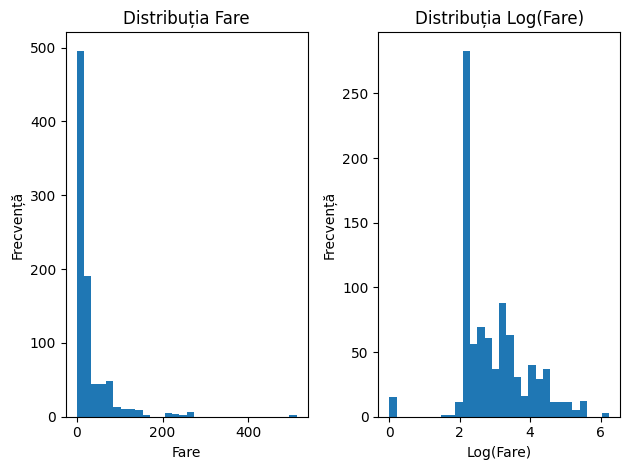

In [18]:
# TODO 3.1 — skewness fare
skew_initial = df["fare"].skew()
print("Skewness pentru fare:", round(skew_initial, 2))

# TODO 3.2 — coloana log_fare + skewness
df["log_fare"] = np.log1p(df["fare"])   # log(1 + fare)
skew_log = df["log_fare"].skew()
print("Skewness pentru log_fare:", round(skew_log, 2))

# TODO 3.3 — două histograme

plt.subplot(1, 2, 1)
plt.hist(df["fare"], bins=30)
plt.title("Distribuția Fare")
plt.xlabel("Fare")
plt.ylabel("Frecvență")


plt.subplot(1, 2, 2)
plt.hist(df["log_fare"], bins=30)
plt.title("Distribuția Log(Fare)")
plt.xlabel("Log(Fare)")
plt.ylabel("Frecvență")

plt.tight_layout()
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [24]:
# TODO 4.1 — limite IQR + număr de outlieri
Q1 = df["fare"].quantile(0.25)
Q3 = df["fare"].quantile(0.75)

IQR = Q3 - Q1

limita_inferioara = Q1 - 1.5 * IQR
limita_superioara = Q3 + 1.5 * IQR
outlieri = df[
    (df["fare"] < limita_inferioara) |
    (df["fare"] > limita_superioara)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Limita inferioară:", round(limita_inferioara, 2))
print("Limita superioară:", round(limita_superioara, 2))
print("Număr de outlieri:", len(outlieri))

# TODO 4.2 — fare_capped (clip) + maxim înainte/după
maxim_inainte = df["fare"].max()

df["fare_capped"] = df["fare"].clip(
    lower=limita_inferioara,
    upper=limita_superioara
)

maxim_dupa = df["fare_capped"].max()
print("\nMaxim fare înainte:", round(maxim_inainte, 2))
print("Maxim fare după:", round(maxim_dupa, 2))

Q1: 7.91
Q3: 31.0
IQR: 23.09
Limita inferioară: -26.72
Limita superioară: 65.63
Număr de outlieri: 116

Maxim fare înainte: 512.33
Maxim fare după: 65.63


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [32]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
coloane = {col.lower(): col for col in df.columns}

sex_col = coloane.get('sex')
embarked_col = coloane.get('embarked')

if sex_col is None or embarked_col is None:
    print("Nu am găsit coloanele necesare.")
    print("Coloanele existente sunt:", df.columns.tolist())
else:
    dummies = pd.get_dummies(
        df[[sex_col, embarked_col]],
        drop_first=True,
        dtype=int
    )

    print("Rezultatul One-Hot Encoding:")
    display(dummies.head())
    print("Dimensiunea:", dummies.shape)

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
from sklearn.preprocessing import StandardScaler


coloane = {col.lower(): col for col in df.columns}

age_col = coloane.get('age')
fare_col = coloane.get('fare_capped')

if age_col is None or fare_col is None:
    print("Nu am găsit coloanele necesare pentru standardizare.")
    print("Coloanele existente sunt:", df.columns.tolist())
else:
    scaler = StandardScaler()

    valori_standardizate = scaler.fit_transform(
        df[[age_col, fare_col]]
    )

    df_standardizat = pd.DataFrame(
        valori_standardizate,
        columns=['age_scaled', 'fare_capped_scaled'],
        index=df.index
    )

    print("Date standardizate:")
    display(df_standardizat.head())

    print("Media și deviația standard:")
    display(
        df_standardizat.describe()
        .loc[['mean', 'std']]
        .round(3)
    )


Nu am găsit coloanele necesare.
Coloanele existente sunt: ['survived', 'pclass', 'age', 'fare', 'log_fare', 'fare_capped', 'sex_male', 'embarked_Q', 'embarked_S']
Date standardizate:


,age_scaled,fare_capped_scaled
0,-0.565736,-0.820552
1,0.663861,2.031623
2,-0.258337,-0.787578
3,0.433312,1.419297
4,0.433312,-0.781471


Media și deviația standard:


,age_scaled,fare_capped_scaled
mean,0.000,0.000
std,1.001,1.001


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:* Am imputat age deoarece este o variabila importanta pentru analiza, iar valorile lipsa pot fi completate cu mediana. Am eliminat deck deoarece avea peste 50% valori lipsa, iar pastrarea sa introduce mai multa incertitudine in analiza